In [1]:
import os

In [2]:
print(os.getcwd())

E:\Data Science\Machine Learning


In [3]:
os.chdir("E:\Data Science\Machine Learning\src")

In [4]:
print(os.getcwd())

E:\Data Science\Machine Learning\src


In [5]:
os.chdir("E:\Data Science\Machine Learning")

In [2]:
# importing libraries:
import matplotlib.pyplot as plt
import numpy as np
from src import util
from src.linear_model import LinearModel

In [3]:
ds1_training_set_path = 'data/ds1_train.csv'
ds1_valid_set_path = 'data/ds1_valid.csv'
ds2_training_set_path = 'data/ds2_train.csv'
ds2_valid_set_path = 'data/ds2_valid.csv'

In [4]:
x_train, y_train = util.load_dataset(ds1_training_set_path, add_intercept=True)
x_valid, y_valid = util.load_dataset(ds1_valid_set_path, add_intercept=True)

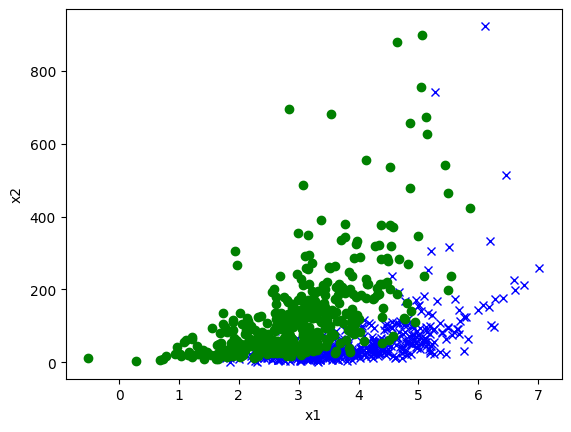

In [9]:
plt.plot(x_train[y_train == 1, 1], x_train[y_train == 1, 2], 'bx', linewidth=2) # for label 1
plt.plot(x_train[y_train == 0, 1], x_train[y_train == 0, 2], 'go', linewidth = 2) # for label 0
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

In [10]:
x_train[y_train == 0, ]

array([[  1.        ,   2.91180854,  60.35961272],
       [  1.        ,   3.77474554, 344.1492843 ],
       [  1.        ,   2.61548828, 178.22208681],
       ...,
       [  1.        ,   3.93767258, 118.24882079],
       [  1.        ,   3.94483407, 105.10648415],
       [  1.        ,   4.30905846, 185.58724675]])

### Implement logistic regression using Newton's Method:

In [11]:
class LogisticRegression(LinearModel):
    """
    Logistic Regression using Newton's method
    
    Example usage:
    >clif = LogisticRegression()
    >clif.fit(x_train, y_train)
    >clif.prediction(x_eval)
    """
    def fit(self, x, y):
        """Run newton's method to minimize J(theta) for logistic regression.

        :param x: Training example inputs. Shape(m,n).
        :param y: Training example labels. Shape(m,).
        """
        def h(theta, x):
            """Vectorized implementation of h_theta(x) = 1 / (1 + exp(-theta^T x)).

            :param theta: Shape (n,).
            :param x:     All training examples of shape (m, n).
            :return:      The hypothesis for all training examples. Shape (m,).
            """
            return 1/(1 + np.exp(-np.dot(x, theta) ) )
            
        def gradient(theta, x, y):
            """Vectorized implementation of the gradient of J(theta).

            :param theta: Shape (n,).
            :param x:     All training examples of shape (m, n).
            :param y:     All labels of shape (m,).
            :return:      The gradient of shape (n,).
            """
            m, _ = x.shape
            return -(1/m) * np.dot(x.T, (y - h(theta,x)))
            
        def hessian(theta, x):
            """Vectorized implementation of the Hessian of J(theta).

            :param theta: Shape (n,).
            :param x:     All training examples of shape (m, n).
            :return:      The Hessian of shape (n, n).
            """
            m, _ = x.shape
            h_theta_x = np.reshape(h(theta, x), (-1, 1))
            return 1 / m * np.dot(x.T, h_theta_x * (1 - h_theta_x) * x)

        def next_theta(theta, x, y):
            """The next theta updated by Newton's Method.

            :param theta: Shape (n,).
            :return:      The updated theta of shape (n,).
            """
            return theta - np.dot(np.linalg.inv(hessian(theta, x)), gradient(theta, x, y))

        m, n = x.shape

        # Initialize theta
        if self.theta is None:
            self.theta = np.zeros(n)

        # Update theta using Newton's Method
        old_theta = self.theta
        new_theta = next_theta(self.theta, x, y)
        while np.linalg.norm(new_theta - old_theta, 1) >= self.eps:
            old_theta = new_theta
            new_theta = next_theta(old_theta, x, y)

        self.theta = new_theta
    def predict(self, x):
        """Make a prediction given new inputs x.

        :param x: Inputs of shape (m, n).
        :return:  Outputs of shape (m,).
        """

        return x @ self.theta >= 0
    

In [14]:
class LogisticRegression2():

    def __init__(self, theta = None, eps = 1e-6):
        self.theta = theta
        self.eps = eps
        
    def fit(self,x,y, alpha = 0.01):
        m,n = x.shape
        def sigmoid(z):
            return 1/(1+np.exp(-z))
        
        def gradient(x,y, theta):
            z = np.dot(x, theta)
            h_x = sigmoid(z) ## gives an (m,1) vector
            return (-1/m) * np.dot(x.T, (y - h_x)) ## (n,m) * (m,1) --> (n,1)

        def hessian(x, theta):
            z = np.dot(x, theta)
            h_x = sigmoid(z)
            h_x = np.reshape(h_x, (-1,1))
            return (1/m) * np.dot(x.T, h_x * (1-h_x) * x) ## should return a (n,n) vector.
        
        def next_theta(x,y, theta):
            H = hessian(x, theta)
            Grd = gradient(x,y,theta)
            return theta - np.dot(np.linalg.inv(H), Grd)
        
        if self.theta is None:
            self.theta = np.zeros(n)
        old_theta = self.theta
        new_theta = next_theta(x,y, old_theta)
        while np.linalg.norm(new_theta - old_theta, 1) >= self.eps:
            old_theta = new_theta
            new_theta = next_theta(x, y, old_theta)
        self.theta = new_theta

    def predict(self, x):
        return x @ self.theta >= 0
        
    def accuracy(self):
        return np.mean(self.predict(self.x) == self.y)

In [15]:
logistic_reg = LogisticRegression2()
logistic_reg.fit(x_train, y_train)

In [18]:
##### accuracy with my logistic regression:
print("Theta is: ", logistic_reg.theta)
print("The accuracy on training set is: ", np.mean(logistic_reg.predict(x_train) == y_train))

Theta is:  [-6.26018491  2.47707251 -0.0299125 ]
The accuracy on training set is:  0.8825


In [76]:
logistic_reg = LogisticRegression()
logistic_reg.fit(x_train, y_train)

Theta is:  [-6.26018491  2.47707251 -0.0299125 ]
The accuracy on training set is:  0.8825


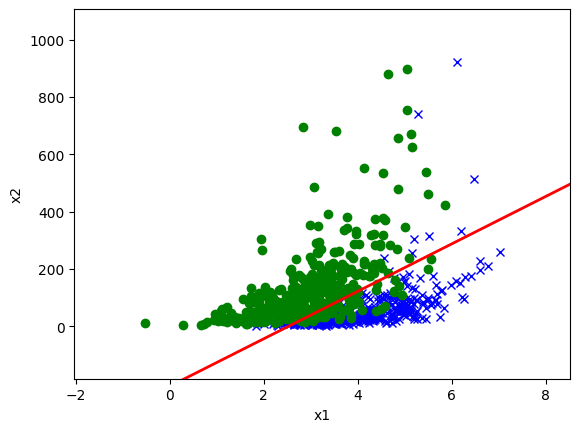

In [84]:
util.plot(x_train, y_train, theta = logistic_reg.theta)
print("Theta is: ", logistic_reg.theta)
print("The accuracy on training set is: ", np.mean(logistic_reg.predict(x_train) == y_train))

The accuracy on validation set is:  0.9


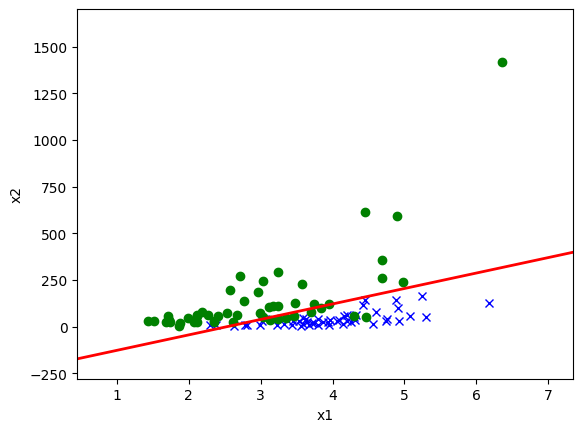

In [86]:
util.plot(x_valid, y_valid, logistic_reg.theta)
print("The accuracy on validation set is: ", np.mean(logistic_reg.predict(x_valid) == y_valid))

### Implementation of Gaussian Discriminant Analysis:

In [88]:
class GDA(LinearModel):
    """Gaussian Discriminant Analysis.

    Example usage:
        > clf = GDA()
        > clf.fit(x_train, y_train)
        > clf.predict(x_eval)
    """

    def fit(self, x, y):
        """Fit a GDA model to training set given by x and y.

        :param x: Training example inputs. Shape (m, n).
        :param y: Training example labels. Shape (m,).
        """

        m, n = x.shape

        phi = np.sum(y) / m
        mu_0 = np.dot(x.T, 1 - y) / np.sum(1 - y)
        mu_1 = np.dot(x.T, y) / np.sum(y)

        # Reshape y to compute pairwise product with mu
        y_reshaped = np.reshape(y, (m, -1))

        # Matrix comprises mu_0 and mu_1 based on the value of y. Shape(m, n)
        mu_x = y_reshaped * mu_1 + (1 - y_reshaped) * mu_0

        x_centered = x - mu_x

        sigma = np.dot(x_centered.T, x_centered) / m
        sigma_inv = np.linalg.inv(sigma)

        # Compute theta and theta_0 according to the conclusion from part (c)
        theta = np.dot(sigma_inv, mu_1 - mu_0)
        theta_0 = 1 / 2 * mu_0 @ sigma_inv @ mu_0 - 1 / 2 * mu_1 @ sigma_inv @ mu_1 - np.log((1 - phi) / phi)

        self.theta = np.insert(theta, 0, theta_0)

    def predict(self, x):
        """Make a prediction given new inputs x.

        :param x: Inputs of shape (m, n).
        :return:  Outputs of shape (m,).
        """

        # Add x_0 = 1 convention to make predictions using theta^T x >= 0
        return util.add_intercept(x) @ self.theta >= 0

### Rewrite plot function to allow a second decision boundary:

In [89]:
def plot(x, y, theta_1, legend_1=None, theta_2=None, legend_2=None, title=None, correction=1.0):
    # Plot dataset
    plt.figure()
    plt.plot(x[y == 1, -2], x[y == 1, -1], 'bx', linewidth=2)
    plt.plot(x[y == 0, -2], x[y == 0, -1], 'go', linewidth=2)

    # Plot decision boundary (found by solving for theta_1^T x = 0)
    x1 = np.arange(min(x[:, -2]), max(x[:, -2]), 0.01)
    x2 = -(theta_1[0] / theta_1[2] * correction + theta_1[1] / theta_1[2] * x1)
    plt.plot(x1, x2, c='red', label=legend_1, linewidth=2)

    # Plot decision boundary (found by solving for theta_2^T x = 0)
    if theta_2 is not None:
        x1 = np.arange(min(x[:, -2]), max(x[:, -2]), 0.01)
        x2 = -(theta_2[0] / theta_1[2] * correction + theta_2[1] / theta_2[2] * x1)
        plt.plot(x1, x2, c='black', label=legend_2, linewidth=2)

    # Add labels, legend and title
    plt.xlabel('x1')
    plt.ylabel('x2')
    if legend_1 is not None or legend_2 is not None:
        plt.legend(loc="upper left")
    if title is not None:
        plt.suptitle(title, fontsize=12)

In [90]:
x_train, y_train = util.load_dataset(ds1_training_set_path)
x_valid, y_valid = util.load_dataset(ds1_valid_set_path)

In [92]:
gda = GDA()
gda.fit(x_train, y_train)

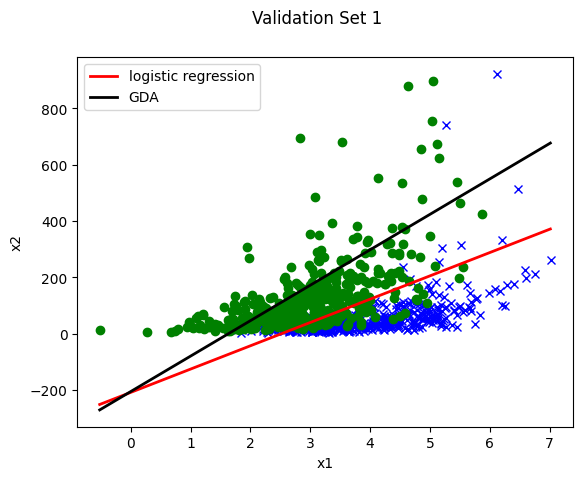

In [95]:
plot(x_train, y_train, theta_1=logistic_reg.theta, legend_1='logistic regression', theta_2=gda.theta, legend_2='GDA', title='Validation Set 1')